# 02 — Data Understanding
**CMPE 412 · NASA C-MAPSS FD001 · CRISP-DM**

This notebook covers **Data Understanding only**. Plots and findings use the official training data. Test and RUL files are read only for structural verification. No RUL targets, training/validation split, scaling, feature removal or model training are performed.

**Colab:** Open the notebook and select Runtime → Run all. The notebook first tries automatic downloads from NASA-linked sources. No file selection is needed if downloading succeeds. If both sources fail, a manual upload prompt accepts a ZIP archive or all three required TXT files together.

**Outputs:** The English report is saved to `docs/02_data_understanding.md`; figures and quality tables are saved to `artifacts/data_understanding/`. The final cell packages these outputs into a ZIP. Download it from Colab's Files panel and save the executed notebook separately using File → Download. Local Jupyter requires the same Python packages; `INPUT_PATHS` can point to local input files.


## 1. Dataset and Scope
[Official NASA dataset page](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data) · [ZIP linked by NASA](https://data.nasa.gov/docs/legacy/CMAPSSData.zip) · [NASA repository outer archive](https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip)

FD001 contains one operating condition (sea level), one fault mode (HPC degradation), 100 training engines, and 100 test engines. Training sequences continue until failure; test sequences stop before failure. `RUL_FD001.txt` contains the true remaining cycles after each engine's last test observation; its values are neither explored nor joined to another table here. Identical engine identifiers in train and test do not identify the same physical engine.

Each sensor record has **26 columns**: `unit`, `cycle`, `setting_1..3`, and `sensor_1..21`. Settings describe operating conditions; sensor names represent their positions in the original schema. Cycles are not hours. Reference: Saxena, Goebel, Simon & Eklund (2008), *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation*, PHM08. This notebook uses the 2 + 3 + 21 schema despite the inconsistent final sensor number in the official page's column description.


## Execution and Validation Note
The saved numerical results were produced using actual NASA FD001 data. The notebook has also been run in Colab. This language revision translates explanations, comments and messages; it does not rerun or alter the numerical analysis. Revised file-loading and preparation code was previously checked locally with the cached NASA archive; the latest network-download fallback has not been rechecked in the Colab interface. Rerunning regenerates inventories, SHA-256 records, findings and the report. Hashes identify input bytes; they are not NASA signatures or independent authenticity guarantees.


In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from datetime import datetime, timezone
import json
import shutil
import hashlib
import zipfile
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
print({"Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__})
SETTINGS = [f"setting_{i}" for i in range(1, 4)]
SENSORS = [f"sensor_{i}" for i in range(1, 22)]
COLUMNS = ["unit", "cycle"] + SETTINGS + SENSORS
REQUIRED = ("train_FD001.txt", "test_FD001.txt", "RUL_FD001.txt")
# Leave empty for automatic download; otherwise provide a ZIP path or all three TXT paths.
INPUT_PATHS = []
STRICT_FD001 = True  # Stop on release shape mismatches; use False only for structural smoke tests.

DOWNLOAD_URLS = (
    "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip",
    "https://data.nasa.gov/docs/legacy/CMAPSSData.zip",
)
CACHE_DIR = Path(".cache/cmapss_fd001")
REPORT_DIR = Path("docs")
ARTIFACT_DIR = Path("artifacts/data_understanding")
for directory in (CACHE_DIR, REPORT_DIR, ARTIFACT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
RUN_UTC = datetime.now(timezone.utc).isoformat()


{'Python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6'}


## 2. Automatic Download and File Resolution
The loader tries the outer ZIP linked by NASA's PCoE repository, followed by the NASA Open Data ZIP. Cached archives are reused on later runs. When `INPUT_PATHS` is provided, those files are used instead. Download or archive-resolution failures trigger the next source; if all sources fail, Colab offers manual upload.

Archives are read in memory without extracting members to disk. Nested ZIPs, directory paths and filename case differences are supported. Size and nesting limits are enforced. Conflicting copies of the same required filename raise an error. HTML error pages are not accepted as ZIP archives. The next cell verifies numerical format and release dimensions; failed checks stop the analysis.


In [2]:
def resolve_files(inputs):
    found = {}
    origins = {}
    budget = [0]
    max_total = 256 * 1024**2
    max_file = 64 * 1024**2
    wanted = {name.lower(): name for name in REQUIRED}
    def visit(label, blob, depth=0):
        if depth > 4:
            raise ValueError("ZIP nesting depth exceeds the limit of 4.")
        if len(blob) > max_file:
            raise ValueError(f"File too large: {label}")
        budget[0] += len(blob)
        if budget[0] > max_total:
            raise ValueError("Total read size exceeds the limit.")
        base = label.rsplit("!", 1)[-1].replace("\\", "/").rsplit("/", 1)[-1].lower()
        if zipfile.is_zipfile(BytesIO(blob)):
            with zipfile.ZipFile(BytesIO(blob)) as z:
                for item in z.infolist():
                    if item.is_dir() or "__MACOSX" in item.filename:
                        continue
                    leaf = item.filename.replace("\\", "/").rsplit("/", 1)[-1].lower()
                    if leaf in wanted or leaf.endswith(".zip"):
                        if item.file_size > max_file:
                            raise ValueError(f"Archive member too large: {item.filename}")
                        visit(f"{label}!{item.filename}", z.read(item), depth+1)
        elif base in wanted:
            name = wanted[base]
            if name in found and found[name] != blob:
                raise ValueError(f"Multiple conflicting copies of {name} were found.")
            found[name] = blob
            origins.setdefault(name, []).append(label)
    for label, blob in inputs.items():
        visit(label, blob)
    missing = set(REQUIRED) - set(found)
    if missing:
        raise FileNotFoundError(f"Missing files: {sorted(missing)}. Upload a ZIP or all three TXT files together.")
    return found, origins

def download_zip(url):
    request = Request(url, headers={"User-Agent": "CMPE412-FD001-DataUnderstanding/1.0"})
    limit = 64 * 1024**2
    with urlopen(request, timeout=30) as response:
        parts, size = [], 0
        while True:
            chunk = response.read(1024**2)
            if not chunk:
                break
            size += len(chunk)
            if size > limit:
                raise ValueError("Download exceeds 64 MiB limit.")
            parts.append(chunk)
    blob = b"".join(parts)
    if not zipfile.is_zipfile(BytesIO(blob)):
        raise ValueError("Response is not a ZIP archive (possibly an HTML error page).")
    return blob


def acquire_files(input_paths, urls, cache_dir):
    if input_paths:
        fileset, locations = resolve_files({str(p): Path(p).read_bytes() for p in input_paths})
        return fileset, locations, "manual local paths"
    for index, url in enumerate(urls, 1):
        cache = cache_dir / f"source_{index}.zip"
        if cache.exists():
            try:
                fileset, locations = resolve_files({f"{url} [cached]": cache.read_bytes()})
                print("Using cached archive:", url)
                return fileset, locations, url
            except (ValueError, OSError, zipfile.BadZipFile) as exc:
                print("Invalid cached archive; downloading again:", str(exc))
                cache.unlink(missing_ok=True)
        try:
            print("Downloading:", url, flush=True)
            blob = download_zip(url)
            fileset, locations = resolve_files({url: blob})
            temporary = cache.with_suffix(".tmp")
            temporary.write_bytes(blob)
            temporary.replace(cache)
            return fileset, locations, url
        except Exception as exc:
            # Report network/archive errors without intercepting user cancellation.
            print(f"Source failed ({type(exc).__name__}): {str(exc)[:250]}")
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Automatic download failed. Set INPUT_PATHS to a ZIP or all three TXT files, then rerun.") from exc
    print("Automatic download failed. Select the NASA ZIP or all three FD001 TXT files together.")
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No files selected. Rerun this cell.")
    fileset, locations = resolve_files(uploaded)
    return fileset, locations, "manual Colab upload"

raw_files, origins, data_source = acquire_files(INPUT_PATHS, DOWNLOAD_URLS, CACHE_DIR)
inventory = pd.DataFrame([{
    "file": name, "bytes": len(raw_files[name]),
    "sha256": hashlib.sha256(raw_files[name]).hexdigest(),
    "source": " | ".join(origins[name])
} for name in REQUIRED])
display(inventory)
inventory.to_csv(ARTIFACT_DIR / "file_inventory.csv", index=False)


Downloading: https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip


,file,bytes,sha256,source
0,train_FD001.txt,3515356,963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8...,https://phm-datasets.s3.amazonaws.com/NASA/6.+...
1,test_FD001.txt,2228855,3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf...,https://phm-datasets.s3.amazonaws.com/NASA/6.+...
2,RUL_FD001.txt,429,a19c8ec94931949d0485bdc35118206e9c81c4547b422e...,https://phm-datasets.s3.amazonaws.com/NASA/6.+...


## 3. Parsing and Structural Validation
Each nonempty whitespace-delimited row must contain 26 numeric fields for a sensor file, or one for the RUL file. Nonfinite values and invalid engine/cycle identifiers are rejected. Expected release dimensions and engine IDs 1–100 are checked. Test measurements and RUL labels are not displayed or explored; only structural checks are performed.


In [3]:
def parse_numeric(blob, width, name):
    try:
        text = blob.decode("utf-8-sig")
    except UnicodeDecodeError as exc:
        raise ValueError(f"{name}: expected UTF-8 text.") from exc
    rows = []
    for lineno, line in enumerate(text.splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != width:
            raise ValueError(f"{name}, line {lineno}: expected {width} columns, found {len(fields)}.")
        try:
            rows.append([float(x) for x in fields])
        except ValueError as exc:
            raise ValueError(f"{name}, line {lineno}: nonnumeric field.") from exc
    if not rows:
        raise ValueError(f"{name}: file is empty.")
    frame = pd.DataFrame(rows)
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError(f"{name}: missing or infinite numeric values are not allowed.")
    return frame

def parse_sensor_file(blob, name):
    frame = parse_numeric(blob, 26, name)
    frame.columns = COLUMNS
    ids = frame[["unit", "cycle"]].to_numpy()
    if not np.isfinite(ids).all() or (ids <= 0).any() or (ids != np.floor(ids)).any():
        raise ValueError(f"{name}: unit/cycle must be positive integers.")
    frame[["unit", "cycle"]] = frame[["unit", "cycle"]].astype("int64")
    return frame

train = parse_sensor_file(raw_files["train_FD001.txt"], "train_FD001.txt")
# These two tables are used only for the shape checks below.
_test_inventory = parse_sensor_file(raw_files["test_FD001.txt"], "test_FD001.txt")
_rul_inventory = parse_numeric(raw_files["RUL_FD001.txt"], 1, "RUL_FD001.txt")
shape_checks = pd.DataFrame([
    ["train_FD001.txt", len(train), train.shape[1], train.unit.nunique(), 20631, 26, 100],
    ["test_FD001.txt", len(_test_inventory), _test_inventory.shape[1], _test_inventory.unit.nunique(), 13096, 26, 100],
    ["RUL_FD001.txt", len(_rul_inventory), _rul_inventory.shape[1], None, 100, 1, None],
], columns=["file", "rows", "columns", "engines", "expected_rows", "expected_columns", "expected_engines"])
shape_checks["matches_release"] = (
    shape_checks.rows.eq(shape_checks.expected_rows)
    & shape_checks["columns"].eq(shape_checks.expected_columns)
    & (shape_checks.expected_engines.isna() | shape_checks.engines.eq(shape_checks.expected_engines))
)
if len(_rul_inventory) != _test_inventory.unit.nunique():
    raise ValueError("RUL row count does not match the number of test engines.")
if STRICT_FD001:
    for name, frame in (("train", train), ("test", _test_inventory)):
        if set(frame.unit.unique()) != set(range(1, 101)):
            raise ValueError(f"{name}: expected engine IDs 1 through 100.")
if (_rul_inventory.to_numpy() < 0).any() or (_rul_inventory.to_numpy() != np.floor(_rul_inventory.to_numpy())).any():
    raise ValueError("RUL inventory must contain nonnegative integer cycle counts.")
display(shape_checks)
shape_checks.to_csv(ARTIFACT_DIR / "shape_checks.csv", index=False)
del _test_inventory, _rul_inventory
if STRICT_FD001 and not shape_checks.matches_release.all():
    raise ValueError("Official FD001 shapes do not match. Check for incorrect or incomplete files.")
display(train.head())
display(pd.DataFrame({"column": COLUMNS, "dtype": train.dtypes.astype(str).values}))


,file,rows,columns,engines,expected_rows,expected_columns,expected_engines,matches_release
0,train_FD001.txt,20631,26,100.0,20631,26,100.0,True
1,test_FD001.txt,13096,26,100.0,13096,26,100.0,True
2,RUL_FD001.txt,100,1,NaN,100,1,NaN,True


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044


,column,dtype
0,unit,int64
1,cycle,int64
2,setting_1,float64
3,setting_2,float64
4,setting_3,float64
5,sensor_1,float64
6,sensor_2,float64
7,sensor_3,float64
8,sensor_4,float64
9,sensor_5,float64


## 4. Training Data Quality
Missing and infinite values, exact duplicate rows, and duplicate `(unit, cycle)` keys are checked separately. Cycle order is evaluated in the original file order, while missing cycles are counted separately. Issues stop the analysis; records are not automatically repaired.


In [4]:
missing_by_column = train.isna().sum()
infinite_by_column = pd.Series(np.isinf(train.to_numpy()).sum(axis=0), index=COLUMNS)
exact_duplicates = int(train.duplicated().sum())
key_duplicates = int(train.duplicated(["unit", "cycle"]).sum())
display(pd.DataFrame({"missing": missing_by_column, "infinite": infinite_by_column}))
print({"rows": len(train), "engines": train.unit.nunique(), "sensors": len(SENSORS),
       "exact_duplicate_rows": exact_duplicates, "duplicate_unit_cycle": key_duplicates})
sequence_rows = []
for unit, group in train.groupby("unit", sort=True):
    original = group.cycle.to_numpy()
    unique = np.sort(np.unique(original))
    sequence_rows.append({"unit": unit, "rows": len(group), "first_cycle": unique[0],
        "last_cycle": unique[-1], "unique_cycles": len(unique),
        "missing_cycles": int(np.maximum(np.diff(unique)-1, 0).sum()),
        "non_increasing_steps": int((np.diff(original) <= 0).sum()),
        "starts_at_one": bool(unique[0] == 1)})
sequence = pd.DataFrame(sequence_rows).set_index("unit")
display(sequence)
sequence_issues = sequence[(sequence.missing_cycles > 0) | (sequence.non_increasing_steps > 0) | ~sequence.starts_at_one]
print("Number of engines with cycle sequence issues:", len(sequence_issues))
if len(sequence_issues):
    display(sequence_issues)
quality_ok = (missing_by_column.sum() == 0 and infinite_by_column.sum() == 0
              and key_duplicates == 0 and len(sequence_issues) == 0)
if not quality_ok:
    raise ValueError("Training quality checks failed: investigate the issues above in the source file; no automatic cleaning was performed.")
train_sorted = train.sort_values(["unit", "cycle"]).reset_index(drop=True)


,missing,infinite
unit,0,0
cycle,0,0
setting_1,0,0
setting_2,0,0
setting_3,0,0
sensor_1,0,0
sensor_2,0,0
sensor_3,0,0
sensor_4,0,0
sensor_5,0,0


{'rows': 20631, 'engines': 100, 'sensors': 21, 'exact_duplicate_rows': 0, 'duplicate_unit_cycle': 0}


,rows,first_cycle,last_cycle,unique_cycles,missing_cycles,non_increasing_steps,starts_at_one
unit,,,,,,,
1,192,1,192,192,0,0,True
2,287,1,287,287,0,0,True
3,179,1,179,179,0,0,True
4,189,1,189,189,0,0,True
5,269,1,269,269,0,0,True
...,...,...,...,...,...,...,...
96,336,1,336,336,0,0,True
97,202,1,202,202,0,0,True
98,156,1,156,156,0,0,True


Number of engines with cycle sequence issues: 0


## 5. Observed Training Record Lengths
After quality checks, each training engine's final cycle represents the observed recording length through failure, not its physical age since manufacture. This is an engine-level EDA summary, not a row-level RUL target. Each engine contributes one observation to these plots.


,observed_lifetime_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


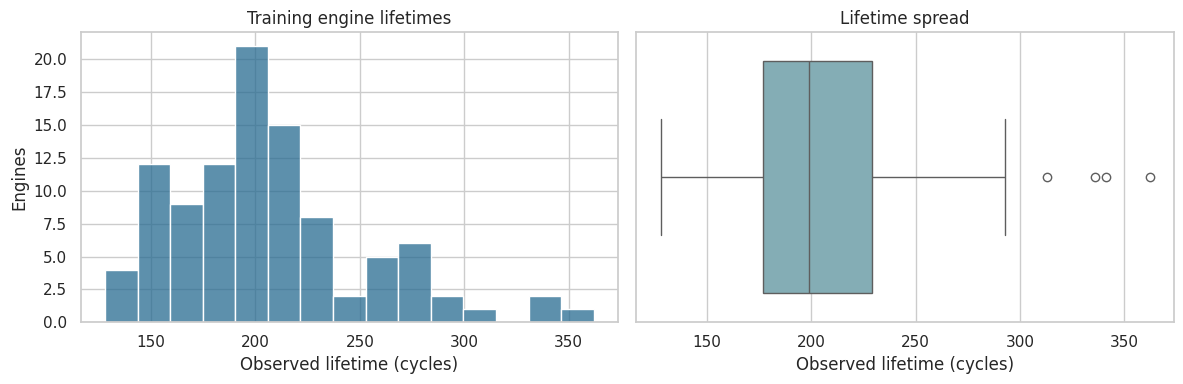

In [5]:
lifetimes = sequence.last_cycle.rename("observed_lifetime_cycles")
display(lifetimes.describe().to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(lifetimes, bins=15, ax=axes[0], color="#276b91")
axes[0].set(xlabel="Observed lifetime (cycles)", ylabel="Engines", title="Training engine lifetimes")
sns.boxplot(x=lifetimes, ax=axes[1], color="#7cb3bd")
axes[1].set(xlabel="Observed lifetime (cycles)", title="Lifetime spread")
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "figure_11.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()


## 6. Selected Sensor Trajectories
The shortest, middle-ranked and longest training records are selected, with engine ID breaking ties. Four predefined sensors are shown using raw measurements and a trailing ten-cycle moving average computed separately for each engine. Smoothing is for visualization only and does not modify the data. Selected examples do not establish a universal pattern across all engines.

### Observation and Data Preparation implication

For the three selected training engines (39, 68 and 69), sensor_4 and sensor_11 generally rise toward the end of the recorded trajectories, while sensor_7 generally falls. These observations are limited to these three engines and do not establish a universal trend across the fleet. Recent sensor trends, such as a trailing-window slope or change in a trailing moving average, are candidates to evaluate in Data Preparation. Compute them separately within each engine using only the current and earlier cycles; choose window sizes and assess usefulness using the engine-level training/validation split, without using the official test set.


Selected training engines: [np.int64(39), np.int64(68), np.int64(69)]


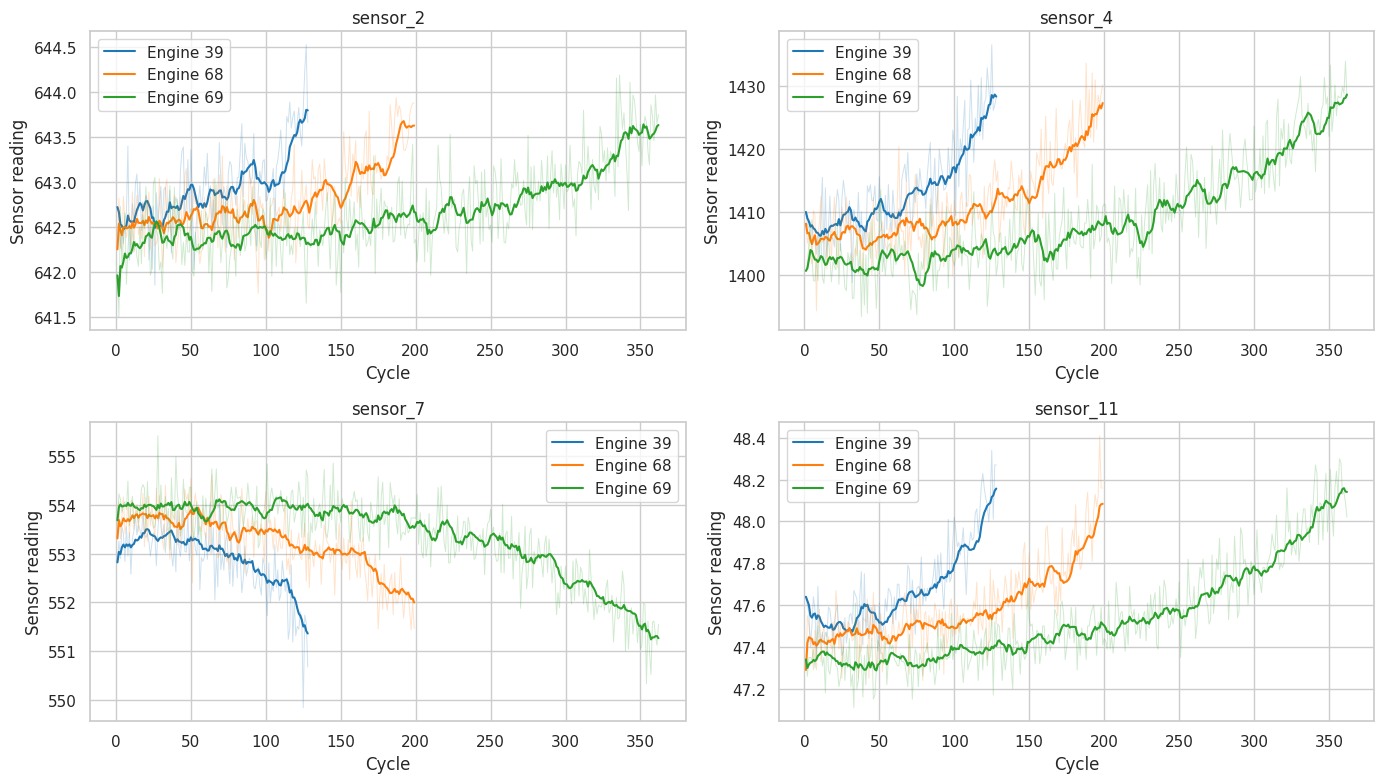

In [6]:
ordered = lifetimes.sort_values(kind="stable")
selected_units = list(dict.fromkeys([ordered.index[0], ordered.index[len(ordered)//2], ordered.index[-1]]))
selected_sensors = ["sensor_2", "sensor_4", "sensor_7", "sensor_11"]
print("Selected training engines:", selected_units)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
colors = sns.color_palette("tab10", len(selected_units))
for ax, sensor in zip(axes.flat, selected_sensors):
    for unit, color in zip(selected_units, colors):
        g = train_sorted[train_sorted.unit.eq(unit)]
        ax.plot(g.cycle, g[sensor], color=color, alpha=.22, linewidth=.7)
        ax.plot(g.cycle, g[sensor].rolling(10, min_periods=1).mean(), color=color, label=f"Engine {unit}")
    ax.set(title=sensor, xlabel="Cycle", ylabel="Sensor reading")
    ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "figure_13.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()


## 7. Sensor Distributions
All 21 sensors are examined. Each observation represents a cycle, so longer engine records contribute more measurements. Sensors have different scales and units; raw magnitudes should not be compared directly. Extreme readings are not removed because they may reflect degradation.


,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,4.660829e-13,1.3000,1.3000,1.3000,1.3000,1.3000


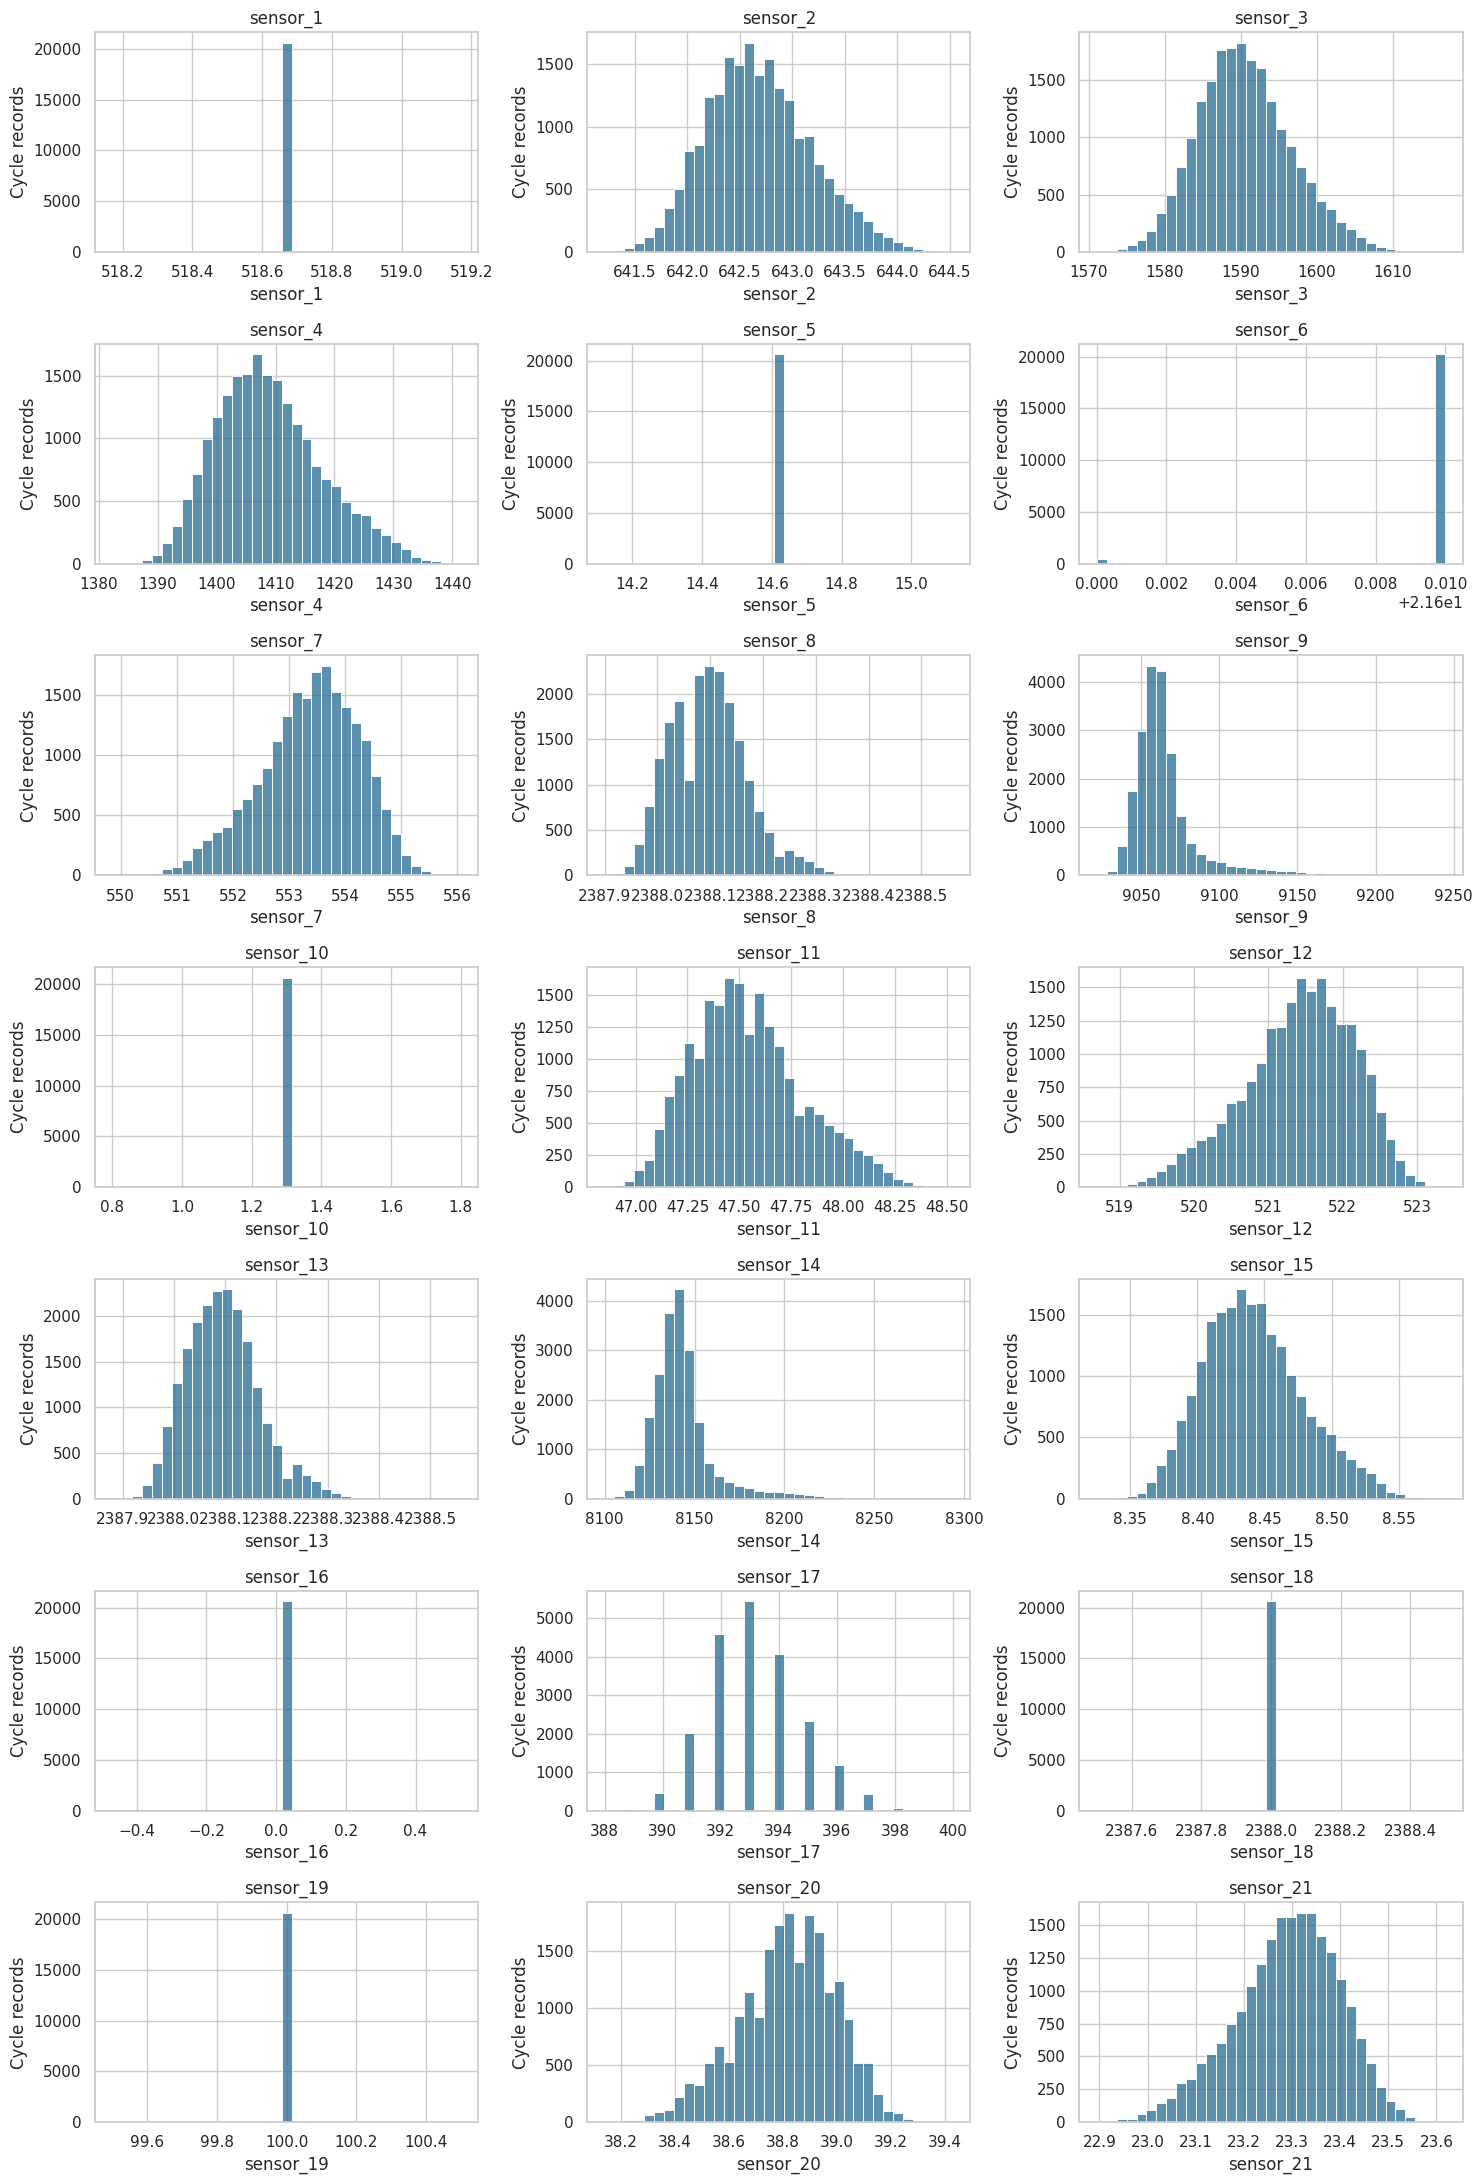

In [7]:
display(train[SENSORS].describe().T)
fig, axes = plt.subplots(7, 3, figsize=(15, 22))
for ax, sensor in zip(axes.flat, SENSORS):
    sns.histplot(data=train, x=sensor, bins=35, ax=ax, color="#276b91")
    ax.set(title=sensor, ylabel="Cycle records")
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "figure_15.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()


## 8. Constant and Low-Variability Columns
Exact constancy is determined by the number of unique values. Nonconstant columns are flagged as exploratory candidates when `range / max(|min|, |max|) ≤ 0.001` or the most frequent value accounts for at least 99% of observations. The relative range of an all-zero constant column is defined as zero. These thresholds are not automatic feature-removal rules; ratios require particular care near zero. Raw variances across different physical units are not directly comparable. Settings are also reported, and no columns are removed.


In [8]:
RELATIVE_RANGE_THRESHOLD = 1e-3
DOMINANT_SHARE_THRESHOLD = .99
features = SETTINGS + SENSORS
stats = train[features].agg(["min", "max", "mean", "std", "var", "nunique"]).T
stats["range"] = stats["max"] - stats["min"]
scale = stats[["min", "max"]].abs().max(axis=1)
stats["relative_range"] = stats["range"].div(scale.replace(0, np.nan)).fillna(0)
stats["dominant_share"] = [train[c].value_counts(normalize=True).iloc[0] for c in features]
stats["constant"] = stats["nunique"].eq(1)
stats["low_variance_candidate"] = (~stats.constant) & (
    stats.relative_range.le(RELATIVE_RANGE_THRESHOLD) | stats.dominant_share.ge(DOMINANT_SHARE_THRESHOLD))
stats["kind"] = ["setting" if c in SETTINGS else "sensor" for c in features]
display(stats)
constant_sensors = [c for c in SENSORS if stats.loc[c, "constant"]]
low_variance_sensors = [c for c in SENSORS if stats.loc[c, "low_variance_candidate"]]
print("Exactly constant sensors:", constant_sensors)
print("Low-variability candidates (excluding constants):", low_variance_sensors)


,min,max,mean,std,var,nunique,range,relative_range,dominant_share,constant,low_variance_candidate,kind
setting_1,-0.0087,0.0087,-0.000009,2.187313e-03,4.784340e-06,158.0,0.0174,2.000000,0.020018,False,False,setting
setting_2,-0.0006,0.0006,0.000002,2.930621e-04,8.588541e-08,13.0,0.0012,2.000000,0.101982,False,False,setting
setting_3,100.0000,100.0000,100.000000,0.000000e+00,0.000000e+00,1.0,0.0000,0.000000,1.000000,True,False,setting
sensor_1,518.6700,518.6700,518.670000,6.537152e-11,4.273435e-21,1.0,0.0000,0.000000,1.000000,True,False,sensor
sensor_2,641.2100,644.5300,642.680934,5.000533e-01,2.500533e-01,310.0,3.3200,0.005151,0.009209,False,False,sensor
sensor_3,1571.0400,1616.9100,1590.523119,6.131150e+00,3.759099e+01,3012.0,45.8700,0.028369,0.001309,False,False,sensor
sensor_4,1382.2500,1441.4900,1408.933782,9.000605e+00,8.101089e+01,4051.0,59.2400,0.041096,0.000969,False,False,sensor
sensor_5,14.6200,14.6200,14.620000,3.394700e-12,1.152399e-23,1.0,0.0000,0.000000,1.000000,True,False,sensor
sensor_6,21.6000,21.6100,21.609803,1.388985e-03,1.929279e-06,2.0,0.0100,0.000463,0.980321,False,True,sensor
sensor_7,549.8500,556.0600,553.367711,8.850923e-01,7.833883e-01,513.0,6.2100,0.011168,0.005623,False,False,sensor


Exactly constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Low-variability candidates (excluding constants): ['sensor_6', 'sensor_8', 'sensor_13']


## 9. Correlation Analysis
Pearson correlations are calculated among training sensors only. Constant sensors have undefined correlations and are excluded. Engine IDs and cycles are not part of the matrix. Temporal dependence, differences between engines and shared degradation trends may affect correlations. Correlation does not establish causality or predictive usefulness on its own.


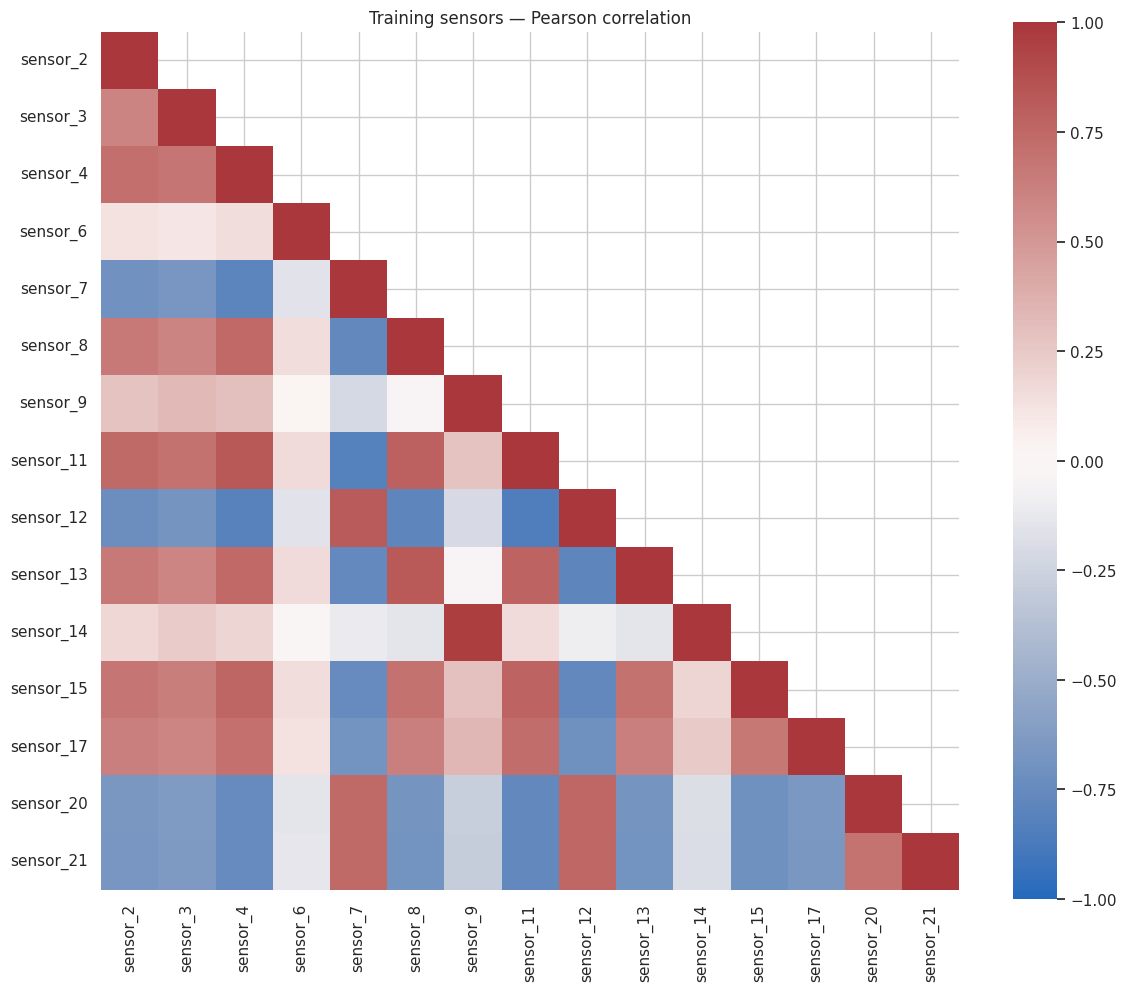

,sensor_a,sensor_b,pearson_r,absolute_r
72,sensor_9,sensor_14,0.963157,0.963157
77,sensor_11,sensor_12,-0.846884,0.846884
31,sensor_4,sensor_11,0.830136,0.830136
63,sensor_8,sensor_13,0.826084,0.826084
52,sensor_7,sensor_11,-0.822805,0.822805
32,sensor_4,sensor_12,-0.815591,0.815591
53,sensor_7,sensor_12,0.812713,0.812713
28,sensor_4,sensor_7,-0.793130,0.793130
84,sensor_12,sensor_13,-0.788441,0.788441
62,sensor_8,sensor_12,-0.786540,0.786540


In [9]:
variable_sensors = [c for c in SENSORS if c not in constant_sensors]
corr = train[variable_sensors].corr(method="pearson")
if len(variable_sensors) >= 2:
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr, mask=np.triu(np.ones(corr.shape, dtype=bool), k=1),
                cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
    plt.title("Training sensors — Pearson correlation")
    plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "figure_19.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("pearson_r").reset_index()
    pairs.columns = ["sensor_a", "sensor_b", "pearson_r"]
    pairs["absolute_r"] = pairs.pearson_r.abs()
    display(pairs.sort_values("absolute_r", ascending=False).head(10))
else:
    pairs = pd.DataFrame(columns=["sensor_a", "sensor_b", "pearson_r", "absolute_r"])
    print("At least two nonconstant sensors are required for correlation.")


## 10. Findings Generated from the Data
The following English summary is generated from the training data read in this run. Results from modified or synthetic files must not be presented as NASA release findings. Whether the selected trajectory examples generalize requires further evaluation.


In [10]:
strongest = "Fewer than two nonconstant sensors were found."
if not pairs.empty:
    p = pairs.sort_values("absolute_r", ascending=False).iloc[0]
    strongest = f"Strongest absolute Pearson pair: {p.sensor_a} / {p.sensor_b}, r={p.pearson_r:.3f}."
summary = f"""
### Training Findings
- Training data: **{len(train):,} rows**, **{train.unit.nunique()} engines**, **21 sensors**, **3 settings**.
- Missing cells: **{int(missing_by_column.sum())}**; infinite values: **{int(infinite_by_column.sum())}**.
- Exact duplicate rows: **{exact_duplicates}**; duplicate engine-cycle keys: **{key_duplicates}**.
- Engines with cycle order, gap, or starting-cycle issues: **{len(sequence_issues)}**.
- Observed training lifetime: **{int(lifetimes.min())}–{int(lifetimes.max())} cycles**; median **{lifetimes.median():.1f}**, mean **{lifetimes.mean():.1f}**.
- Exactly constant sensors: **{', '.join(constant_sensors) or 'none'}**.
- Low-variability candidates under the stated thresholds: **{', '.join(low_variance_sensors) or 'none'}**.
- {strongest} Association does not establish causality or prognostic usefulness on its own.
- The official test and RUL files were used only for inventory and shape verification.
"""
display(Markdown(summary))



### Training Findings
- Training data: **20,631 rows**, **100 engines**, **21 sensors**, **3 settings**.
- Missing cells: **0**; infinite values: **0**.
- Exact duplicate rows: **0**; duplicate engine-cycle keys: **0**.
- Engines with cycle order, gap, or starting-cycle issues: **0**.
- Observed training lifetime: **128–362 cycles**; median **199.0**, mean **206.3**.
- Exactly constant sensors: **sensor_1, sensor_5, sensor_10, sensor_16, sensor_18, sensor_19**.
- Low-variability candidates under the stated thresholds: **sensor_6, sensor_8, sensor_13**.
- Strongest absolute Pearson pair: sensor_9 / sensor_14, r=0.963. Association does not establish causality or prognostic usefulness on its own.
- The official test and RUL files were used only for inventory and shape verification.


## 11. Data Preparation Handoff

1. **Record provenance:** include filenames, SHA-256 hashes, and source links in the project report. Transfer the findings to `docs/02_data_understanding.md`.
2. **Preserve data quality:** retain `(unit, cycle)` keys and within-engine cycle order. Do not delete problematic records without justification or silently fill missing cycles.
3. **Split validation by engine:** in the next stage, separate training engines into training and validation groups. Cycles or overlapping windows from the same engine must not appear in both groups. Do not use `unit` as a model feature.
4. **Recheck EDA decisions:** recompute constant/low-variance and correlation candidates using only the designated training engines. Because this notebook explores the entire official training set, document the potential optimism introduced when refining features against validation results. Consider constant sensors for removal; low variance or high correlation alone is not sufficient justification for removing a feature.
5. **Fit transformations on training data only:** scalers, imputation procedures, and feature-selection rules must not be fitted to validation or test data. Evaluate operating settings separately, and avoid ranking raw variances across different physical units.
6. **Defer targets and windows:** justify the RUL definition, any target cap, window length, and treatment of short engine records in Data Preparation. This notebook does not construct RUL targets.
7. **Reserve the official test set:** use `test_FD001.txt` and `RUL_FD001.txt` only for final evaluation, never for feature, threshold, or hyperparameter selection. Test examples and RUL values are not displayed here.

**Deliverable scope:** this notebook documents data understanding; it does not claim model performance or maintenance decision accuracy. Before ending a Colab session, save the executed notebook using File → Download → Download `.ipynb`.


## 12. Report and Handoff Package
This cell saves English findings, the column dictionary, preparation recommendations, quality tables and figures. Raw dataset files are not included in the output ZIP.


In [11]:
# Generate the report only after successful analysis.
if not STRICT_FD001:
    raise ValueError("Enable STRICT_FD001 before exporting a NASA release report.")
sequence.to_csv(ARTIFACT_DIR / "engine_sequence_checks.csv")
stats.to_csv(ARTIFACT_DIR / "feature_variability.csv")
corr.to_csv(ARTIFACT_DIR / "sensor_correlations.csv")
lifetimes.to_csv(ARTIFACT_DIR / "observed_lifetimes.csv")
pd.DataFrame({"missing": missing_by_column, "infinite": infinite_by_column}).to_csv(ARTIFACT_DIR / "quality_by_column.csv")

column_dictionary = pd.DataFrame([
    {"column": c, "type": str(train[c].dtype),
     "role": "identifier" if c == "unit" else "time index" if c == "cycle" else "operating setting" if c in SETTINGS else "sensor measurement",
     "meaning": "Engine ID within this split; not a model feature" if c == "unit" else "Operational cycle index; not hours" if c == "cycle" else "Operating condition setting; original dataset scale" if c in SETTINGS else "Sensor channel in the original 21-sensor schema; original dataset scale"}
    for c in COLUMNS
])
column_dictionary.to_csv(ARTIFACT_DIR / "column_dictionary.csv", index=False)

def markdown_table(frame):
    # Generate Markdown without an additional dependency such as tabulate.
    def clean(value):
        return str(value).replace("|", "/").replace("\n", " ")
    lines = ["| " + " | ".join(map(clean, frame.columns)) + " |",
             "| " + " | ".join(["---"] * len(frame.columns)) + " |"]
    lines += ["| " + " | ".join(map(clean, row)) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join(lines)

handoff = '## 11. Data Preparation Handoff\n\n1. **Record provenance:** include filenames, SHA-256 hashes, and source links in the project report. Transfer the findings to `docs/02_data_understanding.md`.\n2. **Preserve data quality:** retain `(unit, cycle)` keys and within-engine cycle order. Do not delete problematic records without justification or silently fill missing cycles.\n3. **Split validation by engine:** in the next stage, separate training engines into training and validation groups. Cycles or overlapping windows from the same engine must not appear in both groups. Do not use `unit` as a model feature.\n4. **Recheck EDA decisions:** recompute constant/low-variance and correlation candidates using only the designated training engines. Because this notebook explores the entire official training set, document the potential optimism introduced when refining features against validation results. Consider constant sensors for removal; low variance or high correlation alone is not sufficient justification for removing a feature.\n5. **Fit transformations on training data only:** scalers, imputation procedures, and feature-selection rules must not be fitted to validation or test data. Evaluate operating settings separately, and avoid ranking raw variances across different physical units.\n6. **Defer targets and windows:** justify the RUL definition, any target cap, window length, and treatment of short engine records in Data Preparation. This notebook does not construct RUL targets.\n7. **Reserve the official test set:** use `test_FD001.txt` and `RUL_FD001.txt` only for final evaluation, never for feature, threshold, or hyperparameter selection. Test examples and RUL values are not displayed here.\n\n**Deliverable scope:** this notebook documents data understanding; it does not claim model performance or maintenance decision accuracy. Before ending a Colab session, save the executed notebook using File → Download → Download `.ipynb`.\n'

report = f"""# 02 — Data Understanding

## Scope and provenance

NASA C-MAPSS FD001, CRISP-DM Data Understanding. Generated at {RUN_UTC}.
Source used: {data_source}.

[Official dataset description](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data) · [NASA PCoE repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/).

FD001 simulates one operating condition and one HPC degradation fault mode. Training trajectories end at failure; official test trajectories are truncated. Equal unit IDs in different splits do not establish physical engine identity. Only official training data were explored. Test/RUL files were checked structurally; their values and distributions were not used for analysis or selection. No RUL targets, data splits, transformations or models were produced.

### File inventory

Hashes identify the bytes used in this run; they are not independently authenticated NASA checksums.

{markdown_table(inventory)}

### Release structure checks

{markdown_table(shape_checks)}

{summary}

## Sensor trajectory observations and preparation candidates

For the three selected training engines (39, 68 and 69), sensor_4 and sensor_11 generally rise toward the end of the recorded trajectories, while sensor_7 generally falls. These observations are limited to these three engines and do not establish a universal trend across the fleet. Recent sensor trends, such as a trailing-window slope or change in a trailing moving average, are candidates to evaluate in Data Preparation. Compute them separately within each engine using only the current and earlier cycles; choose window sizes and assess usefulness using the engine-level training/validation split, without using the official test set.

## Interpretation and limitations

Engine lifetime plots summarize the observed run-to-failure recording lengths, not age since manufacture. Sensor histograms weight cycles equally, so longer trajectories contribute more observations. Raw sensor scales differ. The trajectory plots show three reproducibly selected engines and a trailing 10-cycle mean; they do not establish a universal degradation pattern. Constant channels carry no variation in this training release. Low-variability thresholds are exploratory and can flag useful channels; candidate lists do not justify automatic removal. Correlations can arise from shared degradation and engine differences and do not prove causal or predictive value.

No labelled anomaly detection experiment was performed. Large readings, distribution tails and deterioration must not automatically be called anomalous; the next stage must define the intended anomaly and fit/calibrate any Isolation Forest or threshold on its designated training partition.

## Figures

![Observed training lifetimes](../artifacts/data_understanding/figure_11.png)

![Selected sensor trajectories](../artifacts/data_understanding/figure_13.png)

![All sensor distributions](../artifacts/data_understanding/figure_15.png)

![Sensor correlations](../artifacts/data_understanding/figure_19.png)

{handoff}

## Column dictionary

Sensor channels retain their original generic names; physical units are not inferred. See `artifacts/data_understanding/column_dictionary.csv` for reuse.

{markdown_table(column_dictionary)}
"""
report_path = REPORT_DIR / "02_data_understanding.md"
report_path.write_text(report, encoding="utf-8")
manifest = {"generated_utc": RUN_UTC, "source": data_source,
            "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "seaborn": sns.__version__},
            "files": inventory.to_dict(orient="records")}
(ARTIFACT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
# Preserve relative report/figure paths in the ZIP; exclude raw input files.
import tempfile
with tempfile.TemporaryDirectory() as temp:
    root = Path(temp)
    shutil.copytree(REPORT_DIR, root / "docs")
    shutil.copytree(ARTIFACT_DIR, root / "artifacts/data_understanding")
    bundle = shutil.make_archive(str(Path("data_understanding_results").resolve()), "zip", root)
print("English report:", report_path.resolve())
print("Results ZIP:", bundle)
print("Colab: download the ZIP from the Files panel and save the executed notebook separately.")


English report: /content/docs/02_data_understanding.md
Results ZIP: /content/data_understanding_results.zip
Colab: download the ZIP from the Files panel and save the executed notebook separately.
